In [29]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [30]:
# 데이터가져오기
# 데이터 전처리
# 데이터 분리
# PolynomialFeatures 추가
# degree 추가
# 정규화작업 

#### 데이터 학습
# 규제 적용 후 데이터 학습
# alpha 값 변경 후 데이터 학습 확인 

# 데이터 예측
# 정확도 

In [31]:
df = pd.read_csv('data/perch_full.csv')
df.head(5)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43
3,16.2,4.59,2.63
4,17.4,4.59,2.94


In [32]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
1000.0, 1000.0]

In [33]:
df.shape

(56, 3)

In [34]:
len(perch_weight)

56

In [35]:
train_data, test_data, train_label, test_label = train_test_split(df,perch_weight,random_state=42)


In [36]:
poly = PolynomialFeatures(degree=20,include_bias=False)
poly.fit([[2,3]])
train_poly = poly.transform([[2,3]])
train_poly

array([[2.00000000e+00, 3.00000000e+00, 4.00000000e+00, 6.00000000e+00,
        9.00000000e+00, 8.00000000e+00, 1.20000000e+01, 1.80000000e+01,
        2.70000000e+01, 1.60000000e+01, 2.40000000e+01, 3.60000000e+01,
        5.40000000e+01, 8.10000000e+01, 3.20000000e+01, 4.80000000e+01,
        7.20000000e+01, 1.08000000e+02, 1.62000000e+02, 2.43000000e+02,
        6.40000000e+01, 9.60000000e+01, 1.44000000e+02, 2.16000000e+02,
        3.24000000e+02, 4.86000000e+02, 7.29000000e+02, 1.28000000e+02,
        1.92000000e+02, 2.88000000e+02, 4.32000000e+02, 6.48000000e+02,
        9.72000000e+02, 1.45800000e+03, 2.18700000e+03, 2.56000000e+02,
        3.84000000e+02, 5.76000000e+02, 8.64000000e+02, 1.29600000e+03,
        1.94400000e+03, 2.91600000e+03, 4.37400000e+03, 6.56100000e+03,
        5.12000000e+02, 7.68000000e+02, 1.15200000e+03, 1.72800000e+03,
        2.59200000e+03, 3.88800000e+03, 5.83200000e+03, 8.74800000e+03,
        1.31220000e+04, 1.96830000e+04, 1.02400000e+03, 1.536000

In [37]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
# test_poly[:5]
print(test_poly.shape)

(14, 1770)


In [38]:
train_data[:5]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52
6,18.7,5.20,3.12
4,17.4,4.59,2.94
41,36.0,10.61,6.74


In [39]:
ss = StandardScaler()

ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [40]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(train_poly)
print('예측 :', predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도:', score)
print('test 정확도:', score2)

예측 : [ 172.54399451  172.50975988  172.55341357  172.55223598  534.82890473
  171.42768309 1060.08165369  874.90585399 1024.38903292  172.46868188
  172.5270666   172.54610893  172.83386156  168.3903268  1092.8539303
 1025.67175059  172.30341118  172.55365778  167.39284608  879.84454209
  284.69657865  171.36743199  641.78609131  172.55256484  172.44182063
  172.55251909  423.96757018  888.36533683  166.3613589   172.39343538
  668.45660867  172.5503551   172.05430516  172.50105526  973.69561354
  172.65608723  172.55669046  519.11824738  172.53409852  171.39251621
 1096.35736888  379.46362968]
train 정확도: 0.9139326841159604
test 정확도: -5.972173116214384


In [41]:
print(poly.get_feature_names_out())

['length' ' height' ' width' ... ' height^2  width^18' ' height  width^19'
 ' width^20']


In [42]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list: 
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)

    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)

    train_score.append(score)
    test_score.append(score2)

print('완료')


완료


In [43]:
print('train 정확도:', score)
print('test 정확도:', score2)

train 정확도: 0.9847199352612196
test 정확도: 0.9584421179522604


In [44]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

print('train 정확도 :', score)
print('test 정확도 :', score2) 

train 정확도 : 0.9847199352612196
test 정확도 : 0.9584421179522604


C:\Users\mbc\AppData\Local\Temp\ipykernel_2624\3810178061.py:5: UserWarning: Mismatched number of handles and labels: len(handles) = 5 len(labels) = 4
  plt.legend('Train','Test')
C:\Users\mbc\AppData\Local\Temp\ipykernel_2624\3810178061.py:5: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend('Train','Test')


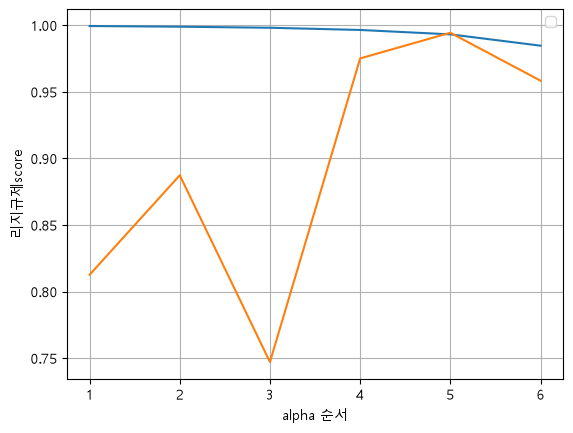

In [47]:
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid()
plt.legend('Train','Test')
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.show()